In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import minimize
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.6f}".format)

# Project directories
PROJECT_DIR = Path.cwd().parent
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "results"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load processed return datasets
asset_returns_gbp = pd.read_csv(
    PROCESSED_DIR / "asset_returns_gbp.csv",
    index_col=0,
    parse_dates=True
)

asset_returns_usd = pd.read_csv(
    PROCESSED_DIR / "asset_returns_usd.csv",
    index_col=0,
    parse_dates=True
)

print("GBP return dimensions:", asset_returns_gbp.shape)
print("USD return dimensions:", asset_returns_usd.shape)

print("\nGBP return date range:")
print(asset_returns_gbp.index.min(), "to", asset_returns_gbp.index.max())

print("\nUSD return date range:")
print(asset_returns_usd.index.min(), "to", asset_returns_usd.index.max())

print("\nAsset columns:")
print(asset_returns_gbp.columns.tolist())

GBP return dimensions: (1253, 5)
USD return dimensions: (1253, 5)

GBP return date range:
2021-10-13 00:00:00 to 2026-10-09 00:00:00

USD return date range:
2021-10-13 00:00:00 to 2026-10-09 00:00:00

Asset columns:
['GLD', 'MSFT', 'QQQ', 'SPY', 'TLT']


In [ ]:
### Split the Datasets into Training and Out-of-Sample Periods

# Define the sample boundaries
TRAIN_START = "2021-10-12"
TRAIN_END = "2023-10-11"
OOS_START = "2023-10-12"
OOS_END = "2026-10-09"

# GBP return samples
gbp_train = asset_returns_gbp.loc[TRAIN_START:TRAIN_END].copy()
gbp_oos = asset_returns_gbp.loc[OOS_START:OOS_END].copy()

# USD return samples
usd_train = asset_returns_usd.loc[TRAIN_START:TRAIN_END].copy()
usd_oos = asset_returns_usd.loc[OOS_START:OOS_END].copy()

# Display sample information
print("GBP TRAINING SAMPLE")
print("Observations:", len(gbp_train))
print("Start:", gbp_train.index.min())
print("End:", gbp_train.index.max())

print("\nGBP OUT-OF-SAMPLE")
print("Observations:", len(gbp_oos))
print("Start:", gbp_oos.index.min())
print("End:", gbp_oos.index.max())

print("\nUSD TRAINING SAMPLE:", usd_train.shape)
print("USD OUT-OF-SAMPLE:", usd_oos.shape)

# Check that the periods do not overlap
assert gbp_train.index.max() < gbp_oos.index.min()
assert usd_train.index.max() < usd_oos.index.min()

# Check that the asset columns are consistent
assert gbp_train.columns.equals(gbp_oos.columns)
assert usd_train.columns.equals(usd_oos.columns)

print("\nSample separation and column checks passed.")

GBP TRAINING SAMPLE
Observations: 502
Start: 2021-10-13 00:00:00
End: 2023-10-11 00:00:00

GBP OUT-OF-SAMPLE
Observations: 751
Start: 2023-10-12 00:00:00
End: 2026-10-09 00:00:00

USD TRAINING SAMPLE: (502, 5)
USD OUT-OF-SAMPLE: (751, 5)

Sample separation and column checks passed.


In [3]:
### Calculate the statistical estimates

# Estimate daily expected returns using the training sample
mu_gbp = gbp_train.mean()
mu_usd = usd_train.mean()

# Estimate daily covariance matrices
cov_gbp = gbp_train.cov()
cov_usd = usd_train.cov()

print("GBP EXPECTED DAILY RETURNS")
display(mu_gbp.to_frame("Mean Daily Return"))

print("\nGBP COVARIANCE MATRIX")
display(cov_gbp)

print("\nUSD EXPECTED DAILY RETURNS")
display(mu_usd.to_frame("Mean Daily Return"))

print("\nUSD COVARIANCE MATRIX")
display(cov_usd)

GBP EXPECTED DAILY RETURNS


,Mean Daily Return
GLD,0.000366
MSFT,0.000699
QQQ,0.000463
SPY,0.000372
TLT,-0.000581



GBP COVARIANCE MATRIX


,GLD,MSFT,QQQ,SPY,TLT
GLD,0.000118,0.000059,0.000059,0.000056,0.000075
MSFT,0.000059,0.000424,0.000324,0.000239,0.000053
QQQ,0.000059,0.000324,0.000320,0.000240,0.000052
SPY,0.000056,0.000239,0.000240,0.000196,0.000045
TLT,0.000075,0.000053,0.000052,0.000045,0.000172



USD EXPECTED DAILY RETURNS


,Mean Daily Return
GLD,0.000147
MSFT,0.000477
QQQ,0.000240
SPY,0.000150
TLT,-0.000797



USD COVARIANCE MATRIX


,GLD,MSFT,QQQ,SPY,TLT
GLD,0.000078,0.000017,0.000017,0.000015,0.000040
MSFT,0.000017,0.000379,0.000280,0.000195,0.000015
QQQ,0.000017,0.000280,0.000275,0.000195,0.000014
SPY,0.000015,0.000195,0.000195,0.000153,0.000007
TLT,0.000040,0.000015,0.000014,0.000007,0.000140


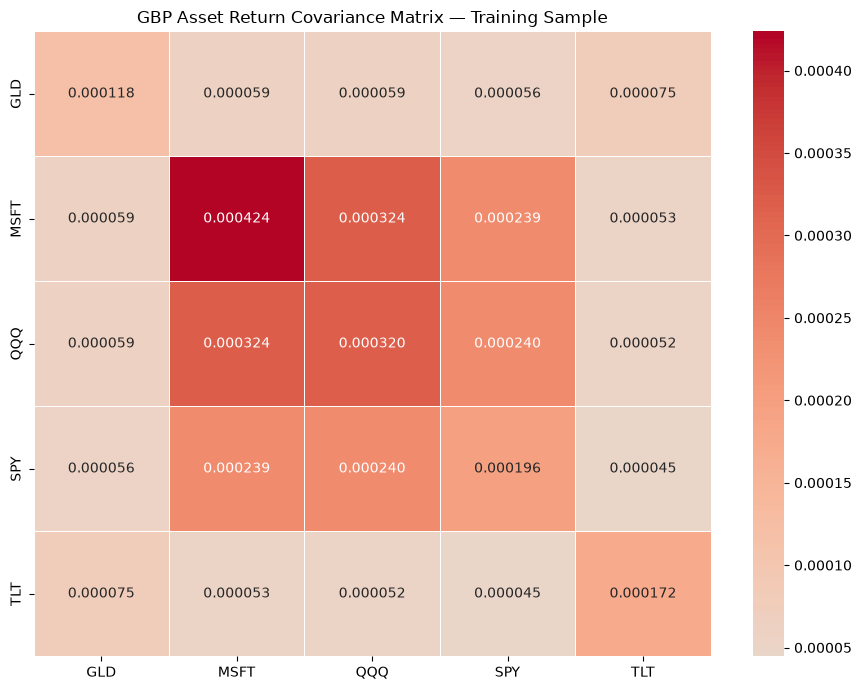

In [4]:
#### Visualize the covariance matrices

plt.figure(figsize=(9, 7))

sns.heatmap(
    cov_gbp,
    annot=True,
    fmt=".6f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("GBP Asset Return Covariance Matrix — Training Sample")
plt.tight_layout()
plt.show()

In [6]:
#### Portfolio Optimisation Setup

def minimum_variance_optimisation(covariance):

    # Number of assets in the portfolio
    n_assets = covariance.shape[0]

    # Starting point: equal allocation across all assets
    initial_weights = np.repeat(1 / n_assets, n_assets)

    # Objective function: portfolio variance
    def portfolio_variance(weights):
        return weights.T @ covariance @ weights

    # Constraint: all portfolio weights must sum to 1
    constraints = ({
        "type": "eq",
        "fun": lambda weights: np.sum(weights) - 1
    })

    # Constraint: no short selling and no weight above 100%
    bounds = tuple((0, 1) for _ in range(n_assets))

    # Run the optimisation
    result = minimize(
        fun=portfolio_variance,
        x0=initial_weights,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"maxiter": 1000, "ftol": 1e-12}
    )

    # Check whether the optimisation was successful
    if not result.success:
        raise RuntimeError(f"Optimisation failed: {result.message}")

    return result.x

In [7]:
# Optimise the GBP portfolio
gbp_weights_array = minimum_variance_optimisation(
    cov_gbp.to_numpy()
)

# Optimise the USD portfolio
usd_weights_array = minimum_variance_optimisation(
    cov_usd.to_numpy()
)

# Convert the results into labelled pandas Series
gbp_weights = pd.Series(
    gbp_weights_array,
    index=gbp_train.columns,
    name="GBP Minimum Variance"
)

usd_weights = pd.Series(
    usd_weights_array,
    index=usd_train.columns,
    name="USD Minimum Variance"
)

# Display the results
weights_comparison = pd.concat(
    [gbp_weights, usd_weights],
    axis=1
)

display(weights_comparison)

,GBP Minimum Variance,USD Minimum Variance
GLD,0.487654,0.502118
MSFT,0.000000,0.000000
QQQ,0.000000,0.000000
SPY,0.266099,0.281840
TLT,0.246247,0.216043


In [8]:
#### Portfolio Risk Calculation

def calculate_portfolio_risk(weights, covariance):

    # Portfolio variance
    daily_variance = weights @ covariance @ weights

    # Daily portfolio volatility
    daily_volatility = np.sqrt(daily_variance)

    # Annualised portfolio volatility
    annual_volatility = daily_volatility * np.sqrt(252)

    return {
        "Daily Variance": daily_variance,
        "Daily Volatility": daily_volatility,
        "Annualised Volatility": annual_volatility
    }


# Equal weights: 20% allocated to each asset
equal_weights = np.repeat(0.20, len(gbp_train.columns))


# GBP portfolio risk
gbp_min_risk = calculate_portfolio_risk(
    gbp_weights.to_numpy(),
    cov_gbp.to_numpy()
)

gbp_equal_risk = calculate_portfolio_risk(
    equal_weights,
    cov_gbp.to_numpy()
)


# USD portfolio risk
usd_min_risk = calculate_portfolio_risk(
    usd_weights.to_numpy(),
    cov_usd.to_numpy()
)

usd_equal_risk = calculate_portfolio_risk(
    equal_weights,
    cov_usd.to_numpy()
)


# Organise the results
risk_comparison = pd.DataFrame(
    {
        "GBP Minimum Variance": gbp_min_risk,
        "GBP Equal Weight": gbp_equal_risk,
        "USD Minimum Variance": usd_min_risk,
        "USD Equal Weight": usd_equal_risk
    }
)

display(risk_comparison)

,GBP Minimum Variance,GBP Equal Weight,USD Minimum Variance,USD Equal Weight
Daily Variance,0.000091,0.000145,0.000052,0.000105
Daily Volatility,0.009528,0.012054,0.007226,0.010225
Annualised Volatility,0.151245,0.191346,0.114710,0.162324


In [9]:
### Constructing out -of-sample portfolios

# Ensure the weights and return columns are in the same order
gbp_weights = gbp_weights.reindex(gbp_oos.columns)
usd_weights = usd_weights.reindex(usd_oos.columns)

# Equal-weight allocation
equal_weights = pd.Series(
    1 / len(gbp_oos.columns),
    index=gbp_oos.columns
)

# Calculate out-of-sample portfolio returns
portfolio_returns = pd.DataFrame(index=gbp_oos.index)

portfolio_returns["GBP_Min_Variance"] = (
    gbp_oos @ gbp_weights
)

portfolio_returns["GBP_Equal_Weight"] = (
    gbp_oos @ equal_weights
)

portfolio_returns["USD_Min_Variance"] = (
    usd_oos @ usd_weights
)

portfolio_returns["USD_Equal_Weight"] = (
    usd_oos @ equal_weights
)

# Inspect the resulting dataset
display(portfolio_returns.head())
display(portfolio_returns.tail())

print("Portfolio return dimensions:", portfolio_returns.shape)
print("Start date:", portfolio_returns.index.min())
print("End date:", portfolio_returns.index.max())
print("Missing observations:", portfolio_returns.isna().sum())

,GBP_Min_Variance,GBP_Equal_Weight,USD_Min_Variance,USD_Equal_Weight
Date,,,,
2023-10-12,-0.011798,-0.010718,-0.009110,-0.008708
2023-10-13,0.029887,0.015400,0.018604,0.004427
2023-10-16,-0.001120,0.005602,-0.002954,0.003170
2023-10-17,-0.006541,-0.007561,-0.001463,-0.002846
2023-10-18,0.004035,-0.002656,0.001610,-0.005328


,GBP_Min_Variance,GBP_Equal_Weight,USD_Min_Variance,USD_Equal_Weight
Date,,,,
2026-10-05,-0.003412,0.001517,0.000090,0.004806
2026-10-06,0.007352,0.007309,0.005624,0.005458
2026-10-07,-0.012806,-0.008113,-0.009433,-0.004494
2026-10-08,0.008672,0.001015,0.004483,-0.002901
2026-10-09,0.008539,0.009304,0.009899,0.010385


Portfolio return dimensions: (751, 4)
Start date: 2023-10-12 00:00:00
End date: 2026-10-09 00:00:00
Missing observations: GBP_Min_Variance    0
GBP_Equal_Weight    0
USD_Min_Variance    0
USD_Equal_Weight    0
dtype: int64


In [10]:
#### Calculate out-of-sample risk statistics

def calculate_oos_statistics(returns):

    results = {}

    for column in returns.columns:

        daily_returns = returns[column]

        # Mean daily return
        mean_daily_return = daily_returns.mean()

        # Daily volatility
        daily_volatility = daily_returns.std()

        # Annualised volatility
        annualised_volatility = daily_volatility * np.sqrt(252)

        # Cumulative return over the full period
        cumulative_return = (1 + daily_returns).prod() - 1

        # Annualised compounded return
        annualised_return = (
            (1 + cumulative_return) ** (252 / len(daily_returns)) - 1
        )

        # Portfolio value index, starting at 1
        wealth_index = (1 + daily_returns).cumprod()

        # Previous highest portfolio value
        running_peak = wealth_index.cummax()

        # Drawdown from the previous peak
        drawdown = wealth_index / running_peak - 1

        # Maximum drawdown
        maximum_drawdown = drawdown.min()

        results[column] = {
            "Mean Daily Return": mean_daily_return,
            "Daily Volatility": daily_volatility,
            "Annualised Volatility": annualised_volatility,
            "Cumulative Return": cumulative_return,
            "Annualised Return": annualised_return,
            "Maximum Drawdown": maximum_drawdown
        }

    return pd.DataFrame(results).T


oos_statistics = calculate_oos_statistics(portfolio_returns)

display(oos_statistics)

,Mean Daily Return,Daily Volatility,Annualised Volatility,Cumulative Return,Annualised Return,Maximum Drawdown
GBP_Min_Variance,0.000712,0.009201,0.146064,0.653466,0.183813,-0.127885
GBP_Equal_Weight,0.000690,0.009129,0.144918,0.627481,0.177538,-0.138692
USD_Min_Variance,0.000830,0.008267,0.131242,0.817241,0.221931,-0.123038
USD_Equal_Weight,0.000779,0.008117,0.128854,0.751645,0.206949,-0.125943


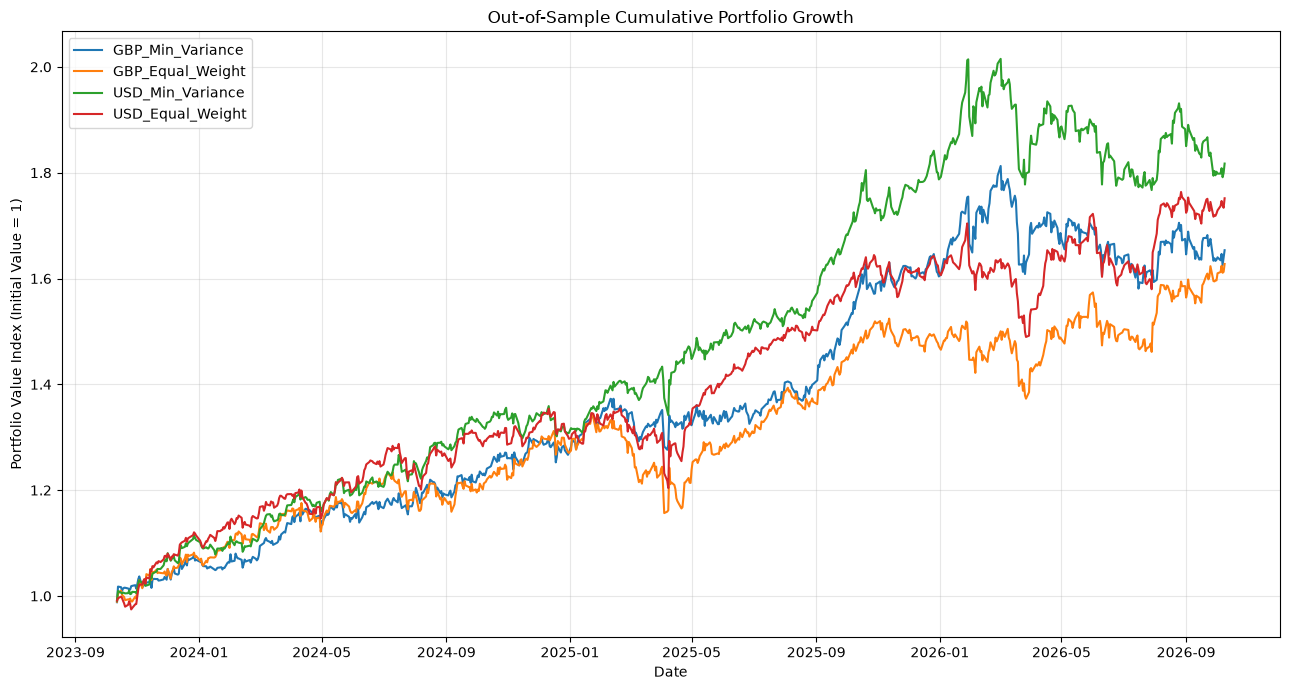

In [ ]:
### Visualise cumulative portfolio value

# Calculate cumulative portfolio growth
cumulative_returns = (1 + portfolio_returns).cumprod()

# Plot the four portfolios
plt.figure(figsize=(13, 7))

for column in cumulative_returns.columns:
    plt.plot(
        cumulative_returns.index,
        cumulative_returns[column],
        label=column
    )

plt.title("Out-of-Sample Cumulative Portfolio Growth")
plt.xlabel("Date")
plt.ylabel("Portfolio Value Index (Initial Value = 1)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()